# BCSE331P – Exploratory Data Analysis
## Assessment 8: K-Means and Hierarchical Clustering
**Dataset:** `recid.csv` (1445 rows; columns: rownames, black, alcohol, drugs, super, married, felon, workprg, property, person, priors, educ, rules, age, tserved, follow, durat, cens, ldurat).

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
URL = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/recid.csv"

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

## Part A – K-Means Clustering
**Q1. Load the dataset**

In [3]:
df = pd.read_csv(URL)

**Q2. View the dataset**

In [4]:
print(df.shape); df.head()

(1445, 19)


,rownames,black,alcohol,drugs,super,married,felon,workprg,property,person,priors,educ,rules,age,tserved,follow,durat,cens,ldurat
0,1,0,1,0,1,1,0,1,0,0,0,7,2,441,30,72,72,1,4.276666
1,2,1,0,0,1,0,1,1,1,0,0,12,0,307,19,75,75,1,4.317488
2,3,0,0,0,0,0,0,1,1,0,0,9,5,262,27,81,9,0,2.197225
3,4,0,0,1,1,0,1,1,1,0,2,9,3,253,38,76,25,0,3.218876
4,5,0,0,1,1,0,0,0,0,0,0,9,0,244,4,81,81,1,4.394449


**Q3. Check missing values**

In [5]:
df.isna().sum()

,0
rownames,0
black,0
alcohol,0
drugs,0
super,0
married,0
felon,0
workprg,0
property,0
person,0


**Q4. Dependent variable distribution** (`cens`: 1 = censored / no return to prison, 0 = returned)

In [6]:
df["cens"].value_counts()

,count
cens,
1,893
0,552


**Q5. Select only numerical features**

In [7]:
features = ["priors", "educ", "rules", "age", "tserved", "follow", "durat"]   # continuous numerical features
X = df[features]                      # id (rownames), 0/1 flags, target (cens) and ldurat removed
X.head()

,priors,educ,rules,age,tserved,follow,durat
0,0,7,2,441,30,72,72
1,0,12,0,307,19,75,75
2,0,9,5,262,27,81,9
3,2,9,3,253,38,76,25
4,0,9,0,244,4,81,81


**Q6. Standardize the data**

In [8]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=features)
X_scaled.describe().loc[["mean", "std"]].round(3)

,priors,educ,rules,age,tserved,follow,durat
mean,0.0,-0.0,0.0,0.0,-0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0


**Q7. K-Means with 2 centers**

In [9]:
km2 = KMeans(n_clusters=2, n_init=25, random_state=42).fit(X_scaled)

**Q8. K-Means results**

In [10]:
print("Cluster sizes:", np.bincount(km2.labels_))
print("Within-cluster sum of squares:", round(km2.inertia_, 2))
print("Between/Total SS: {:.1f}%".format(100 * (1 - km2.inertia_ / ((X_scaled - X_scaled.mean())**2).sum().sum())))
print("First 10 cluster assignments:", km2.labels_[:10])

Cluster sizes: [1172  273]
Within-cluster sum of squares: 8539.09
Between/Total SS: 15.6%
First 10 cluster assignments: [0 0 1 1 0 0 0 0 0 0]


**Q9. Cluster centers**

In [11]:
print("Centers (standardized):"); display(pd.DataFrame(km2.cluster_centers_, columns=features).round(3))
print("Centers (original units):"); display(pd.DataFrame(scaler.inverse_transform(km2.cluster_centers_), columns=features).round(2))

Centers (standardized):


,priors,educ,rules,age,tserved,follow,durat
0,-0.237,0.052,-0.270,-0.051,-0.293,0.008,0.185
1,1.017,-0.225,1.158,0.219,1.256,-0.035,-0.793


Centers (original units):


,priors,educ,rules,age,tserved,follow,durat
0,0.76,9.83,0.57,339.26,13.05,74.91,60.41
1,4.33,9.15,3.84,371.96,45.51,74.76,33.73


**Q10. WCSS for K = 1 to 10**

In [12]:
K = list(range(1, 11))
wcss = [KMeans(n_clusters=k, n_init=25, random_state=42).fit(X_scaled).inertia_ for k in K]
pd.DataFrame({"K": K, "WCSS": np.round(wcss, 2)})

,K,WCSS
0,1,10115.00
1,2,8539.09
2,3,7159.27
3,4,6212.24
4,5,5588.33
5,6,5039.67
6,7,4749.00
7,8,4476.57
8,9,4229.04
9,10,4013.35


**Q11. Elbow plot**

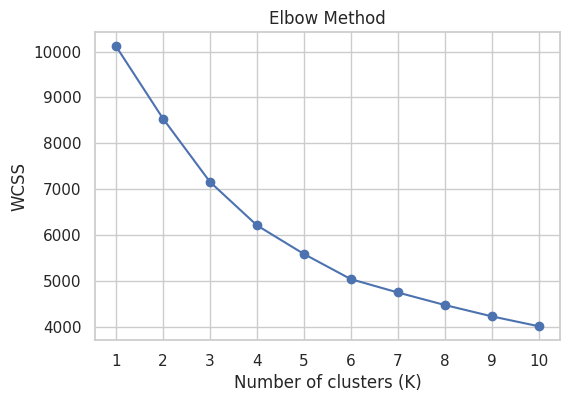

Elbow recommendation: K = 4


In [13]:
plt.figure(figsize=(6,4)); plt.plot(K, wcss, "bo-")
plt.title("Elbow Method"); plt.xlabel("Number of clusters (K)"); plt.ylabel("WCSS"); plt.xticks(K); plt.show()

# elbow = point farthest from the straight line joining first and last WCSS values
kx = (np.array(K) - K[0]) / (K[-1] - K[0]); wy = (np.array(wcss) - min(wcss)) / (max(wcss) - min(wcss))
dist = np.abs(kx + wy - 1) / np.sqrt(2)
k_opt = K[int(np.argmax(dist))]
print("Elbow recommendation: K =", k_opt)

**Q12. K-Means using the elbow recommendation**

In [14]:
km_opt = KMeans(n_clusters=k_opt, n_init=25, random_state=42).fit(X_scaled)
df["cluster"] = km_opt.labels_
print("Cluster sizes:\n", df["cluster"].value_counts().sort_index())
display(df.groupby("cluster")[features].mean().round(2))
display(pd.crosstab(df["cluster"], df["cens"]))

Cluster sizes:
 cluster
0    357
1    770
2    102
3    216
Name: count, dtype: int64


,priors,educ,rules,age,tserved,follow,durat
cluster,,,,,,,
0,1.09,9.98,1.06,296.76,19.00,75.23,18.04
1,0.47,10.36,0.64,312.79,13.81,74.88,73.32
2,2.53,9.48,7.36,325.10,65.60,74.37,42.13
3,4.91,7.00,0.42,551.86,16.73,74.56,59.34


cens,0,1
cluster,,
0,357,0
1,65,705
2,60,42
3,70,146


## Part B – Hierarchical Clustering
**Q1–Q3.** Load, view and check missing values (same dataset)

In [15]:
dfh = pd.read_csv(URL); print(dfh.shape); display(dfh.head()); print(dfh.isna().sum().sum(), "missing values")

(1445, 19)


,rownames,black,alcohol,drugs,super,married,felon,workprg,property,person,priors,educ,rules,age,tserved,follow,durat,cens,ldurat
0,1,0,1,0,1,1,0,1,0,0,0,7,2,441,30,72,72,1,4.276666
1,2,1,0,0,1,0,1,1,1,0,0,12,0,307,19,75,75,1,4.317488
2,3,0,0,0,0,0,0,1,1,0,0,9,5,262,27,81,9,0,2.197225
3,4,0,0,1,1,0,1,1,1,0,2,9,3,253,38,76,25,0,3.218876
4,5,0,0,1,1,0,0,0,0,0,0,9,0,244,4,81,81,1,4.394449


0 missing values


**Q4. Select only numerical attributes**   **Q5. Standardize (scale)**

In [16]:
Xh = dfh[features]
Xh_scaled = StandardScaler().fit_transform(Xh)

**Q6. Euclidean distance**

In [17]:
from scipy.spatial.distance import pdist
d = pdist(Xh_scaled, metric="euclidean")
print("Number of pairwise distances:", len(d))

Number of pairwise distances: 1043290


**Q7. Hierarchical clustering using Ward's method**

In [18]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
Z = linkage(d, method="ward")

**Q8. Dendrogram**

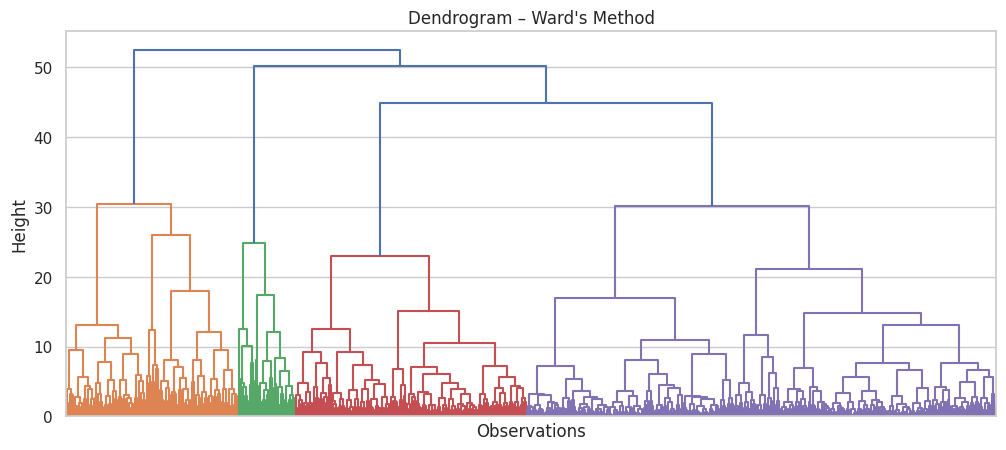

In [19]:
plt.figure(figsize=(12, 5))
dendrogram(Z, no_labels=True, color_threshold=Z[-3, 2])
plt.title("Dendrogram – Ward's Method"); plt.xlabel("Observations"); plt.ylabel("Height"); plt.show()

**Q9. Cut into 3 clusters and display assignments**

In [20]:
dfh["cluster"] = fcluster(Z, t=3, criterion="maxclust")
dfh[["rownames", "cluster"]].head(15)

,rownames,cluster
0,1,1
1,2,3
2,3,3
3,4,3
4,5,3
5,6,3
6,7,3
7,8,3
8,9,1
9,10,3


**Q10. Number of samples in each cluster**

In [21]:
dfh["cluster"].value_counts().sort_index().to_frame("Samples")

,Samples
cluster,
1,268
2,88
3,1089
